# Kalman Filter Parameter Sweep

Results from phased parameter tuning of the 3D ball-tracking Kalman filter.

Each phase isolates one parameter dimension, finds the best value, then locks it
for subsequent phases.

## How to use

1. In `src/evaluate.py`, set `PHASE` and `CONFIGS` for the phase you want to run.
2. Run the sweep inside Docker:  
   ```bash
   docker compose run perception-x86 bash -lc "python src/evaluate.py"
   ```
3. Results are saved to `output/sweep_phase_N.csv` and `output/ade_fde_phase_N.png`.
4. Come back here, set `PHASE` below to the phase number, and run the cells to inspect.

In [46]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("../output")
PHASE = 1  # change this to view a different phase

In [47]:
%pip install -q pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


## Load results

In [48]:
csv_path = OUTPUT_DIR / f"sweep_phase_{PHASE}.csv"
df = pd.read_csv(csv_path)
print(f"Loaded {csv_path} - {len(df)} rows")
df.head()

Loaded ../output/sweep_phase_1.csv - 40 rows


,config,velocity_process_noise,position_process_noise,measurement_noise_x,measurement_noise_y,measurement_noise_z,sequence,n,mean_ade_m,mean_fde_m,max_ade_m,max_fde_m,latency_mean_ms,latency_p95_ms,latency_max_ms,throughput_fps,ram_peak_mb,gpu_peak_mb
0,vpn_0.001,0.001,0.0001,0.000064,0.000121,0.000064,HD1080_one_ball_straight_line_21-34-15,65,0.0153,0.0252,0.0866,0.1395,10.75,8.84,339.37,29.48,2318.3,396.4
1,vpn_0.001,0.001,0.0001,0.000064,0.000121,0.000064,HD1080_one_ball_diagonal_21-34-29,91,0.0104,0.0177,0.0369,0.0573,8.58,8.79,8.81,35.81,2439.1,346.4
2,vpn_0.001,0.001,0.0001,0.000064,0.000121,0.000064,HD1080_one_ball_diagonal_21-34-44,134,0.0112,0.0189,0.1712,0.2944,8.74,8.84,8.93,33.20,2480.6,346.4
3,vpn_0.001,0.001,0.0001,0.000064,0.000121,0.000064,HD1080_one_ball_diagonal_21-35-05,123,0.0104,0.0172,0.0437,0.0742,8.70,8.82,8.94,35.79,2550.8,346.4
4,vpn_0.001,0.001,0.0001,0.000064,0.000121,0.000064,HD1080_one_ball_diagonal_21-35-18,99,0.0162,0.0263,0.0417,0.0638,8.66,8.85,9.01,35.81,2552.1,346.4


## Config parameters

Which KF parameters were tested in this phase.

In [49]:
param_cols = [c for c in df.columns if c.endswith("_noise")]
if param_cols:
    configs = df.groupby("config")[param_cols].first().reset_index()
    display(configs)
else:
    print("No parameter columns found (older CSV format).")
    print("Configs:", df["config"].unique())

,config,velocity_process_noise,position_process_noise
0,vpn_0.001,0.001,0.0001
1,vpn_0.005,0.005,0.0001
2,vpn_0.01,0.010,0.0001
3,vpn_0.02,0.020,0.0001
4,vpn_0.05,0.050,0.0001
5,vpn_0.1,0.100,0.0001
6,vpn_0.2,0.200,0.0001
7,vpn_0.5,0.500,0.0001


## Per-sequence results

In [50]:
result_cols = ["config", "sequence", "n", "mean_ade_m", "mean_fde_m", "max_ade_m", "max_fde_m"]
display(df[[c for c in result_cols if c in df.columns]])

,config,sequence,n,mean_ade_m,mean_fde_m,max_ade_m,max_fde_m
0,vpn_0.001,HD1080_one_ball_straight_line_21-34-15,65,0.0153,0.0252,0.0866,0.1395
1,vpn_0.001,HD1080_one_ball_diagonal_21-34-29,91,0.0104,0.0177,0.0369,0.0573
2,vpn_0.001,HD1080_one_ball_diagonal_21-34-44,134,0.0112,0.0189,0.1712,0.2944
3,vpn_0.001,HD1080_one_ball_diagonal_21-35-05,123,0.0104,0.0172,0.0437,0.0742
4,vpn_0.001,HD1080_one_ball_diagonal_21-35-18,99,0.0162,0.0263,0.0417,0.0638
5,vpn_0.005,HD1080_one_ball_straight_line_21-34-15,65,0.0138,0.0227,0.0866,0.1395
6,vpn_0.005,HD1080_one_ball_diagonal_21-34-29,91,0.0071,0.0121,0.0369,0.0573
7,vpn_0.005,HD1080_one_ball_diagonal_21-34-44,134,0.0080,0.0135,0.1713,0.2946
8,vpn_0.005,HD1080_one_ball_diagonal_21-35-05,123,0.0075,0.0118,0.0437,0.0742
9,vpn_0.005,HD1080_one_ball_diagonal_21-35-18,99,0.0117,0.0185,0.0425,0.0607


## Overall summary (aggregated across all sequences)

In [51]:
summary = df.groupby("config").agg(
    n=("n", "sum"),
    mean_ade=("mean_ade_m", "mean"),
    mean_fde=("mean_fde_m", "mean"),
    max_ade=("max_ade_m", "max"),
    max_fde=("max_fde_m", "max"),
).reset_index()

best = summary.loc[summary["mean_fde"].idxmin()]
print(f"Best config by mean FDE: {best['config']} (FDE={best['mean_fde']:.4f}m, ADE={best['mean_ade']:.4f}m)")
display(summary)

Best config by mean FDE: vpn_0.02 (FDE=0.0147m, ADE=0.0091m)


,config,n,mean_ade,mean_fde,max_ade,max_fde
0,vpn_0.001,512,0.01270,0.02106,0.1712,0.2944
1,vpn_0.005,512,0.00962,0.01572,0.1713,0.2946
2,vpn_0.01,512,0.00918,0.01488,0.1714,0.2949
3,vpn_0.02,512,0.00910,0.01466,0.1718,0.2954
4,vpn_0.05,512,0.00946,0.01514,0.1726,0.2968
5,vpn_0.1,512,0.00990,0.01590,0.1740,0.2990
6,vpn_0.2,512,0.01048,0.01684,0.1765,0.3031
7,vpn_0.5,512,0.01124,0.01822,0.1823,0.3127


## ADE / FDE bar chart

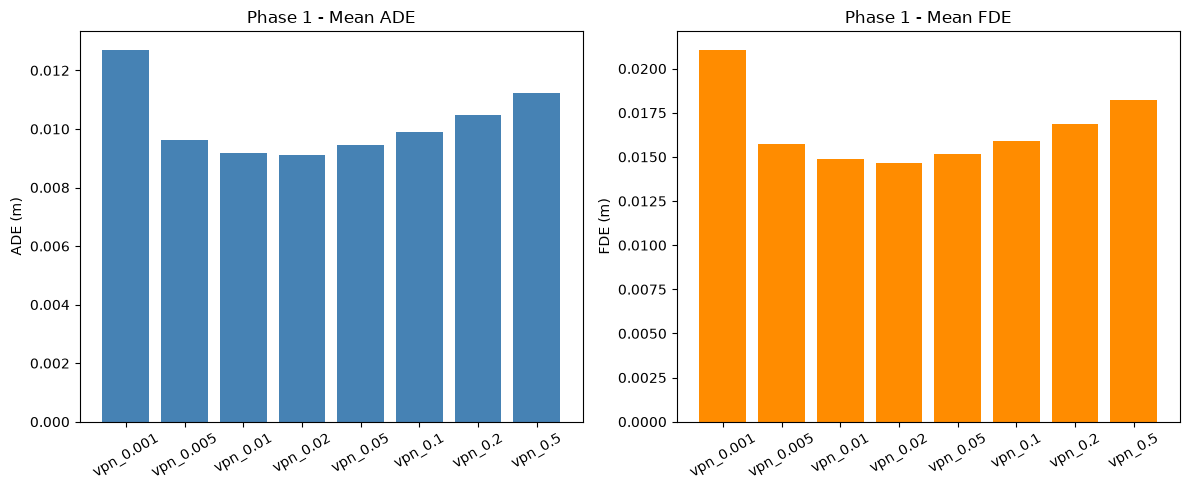

In [52]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.bar(summary["config"], summary["mean_ade"], color="steelblue")
ax1.set_ylabel("ADE (m)")
ax1.set_title(f"Phase {PHASE} - Mean ADE")
ax1.tick_params(axis="x", rotation=30)

ax2.bar(summary["config"], summary["mean_fde"], color="darkorange")
ax2.set_ylabel("FDE (m)")
ax2.set_title(f"Phase {PHASE} - Mean FDE")
ax2.tick_params(axis="x", rotation=30)

fig.tight_layout()
plt.show()

## Per-sequence breakdown

FDE per config, broken out by sequence - helps spot if one trajectory type dominates.

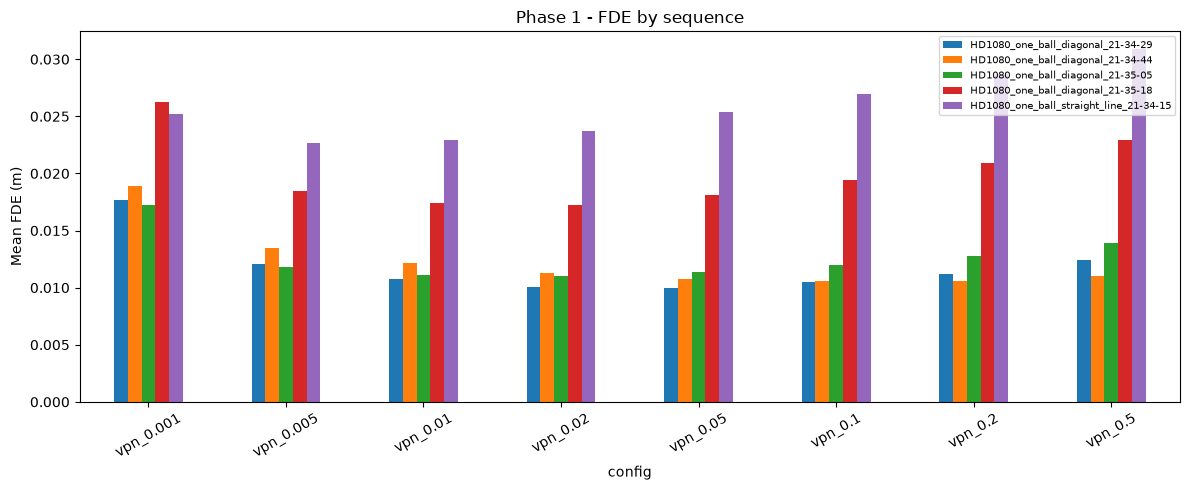

In [53]:
pivot = df.pivot_table(index="config", columns="sequence", values="mean_fde_m")

fig, ax = plt.subplots(figsize=(12, 5))
pivot.plot(kind="bar", ax=ax)
ax.set_ylabel("Mean FDE (m)")
ax.set_title(f"Phase {PHASE} - FDE by sequence")
ax.tick_params(axis="x", rotation=30)
ax.legend(fontsize=7, loc="upper right")
fig.tight_layout()
plt.show()

## Cross-phase comparison

Compare the best config from each phase run so far.

In [54]:
phase_bests = []
for p in range(1, PHASE + 1):
    path = OUTPUT_DIR / f"sweep_phase_{p}.csv"
    if not path.exists():
        continue
    phase_df = pd.read_csv(path)
    s = phase_df.groupby("config").agg(
        mean_ade=("mean_ade_m", "mean"),
        mean_fde=("mean_fde_m", "mean"),
    )
    best_row = s.loc[s["mean_fde"].idxmin()]
    phase_bests.append({"phase": p, "config": best_row.name,
                        "mean_ade": best_row["mean_ade"], "mean_fde": best_row["mean_fde"]})

if phase_bests:
    comparison = pd.DataFrame(phase_bests)
    display(comparison)
else:
    print("No phase results found.")

,phase,config,mean_ade,mean_fde
0,1,vpn_0.02,0.0091,0.01466
